# NNCv Project — Tree Species Classification with Transfer Learning
**From Pixels to Probabilities — ResNet18 vs ResNet50 on urban street trees**

Group: Tomi, Jaakko, Timo

This notebook is built on top of the Lecture 6 notebook (same structure and helper functions).
The MNIST + DeepMLP parts are replaced with the tree dataset and pretrained ResNet models,
following the PyTorch [transfer learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).

- Dataset: [Tree Dataset of Urban Street – Classification Tree](https://www.kaggle.com/datasets/erickendric/tree-dataset-of-urban-street-classification-tree) (~4800 photos, 23 species)
- Models: **ResNet18** (~11M parameters) and **ResNet50** (~24M parameters), pretrained on ImageNet
- Evaluation on a separate test set: accuracy, precision, recall, F1, confusion matrix, n-best (top-n) accuracy
- Round 2: error analysis → improved training → comparison

Run with a GPU (Colab: Runtime → Change runtime type → T4 GPU).

## 0. Setup & Utilities

In [1]:
# Core imports
import os, random, time, copy
import numpy as np
import torch, torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms as T
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_recall_fscore_support, classification_report)

# Optional: nicer plots
plt.rcParams["figure.dpi"] = 90

# Reproducibility + device helpers (same as in the lecture notebook)
def setup(device_preference="cuda", seed=42):
    use_cuda = torch.cuda.is_available() and device_preference == "cuda"
    device = torch.device("cuda" if use_cuda else "cpu")
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    if use_cuda:
        torch.cuda.manual_seed_all(seed)
        # For speed (slightly less deterministic); set to False + deterministic=True if you need strict determinism
        torch.backends.cudnn.benchmark = True
    return device

SEED = 42
device = setup(seed=SEED)

# On Windows + Jupyter, worker processes can't see a Dataset class defined in the notebook -> use 0 there
NUM_WORKERS = 0 if os.name == "nt" else 2

device

device(type='cuda')

In [2]:
# Trained models are saved outside the project folder (they are too big for the submission zip).
# In Colab -> Google Drive, otherwise -> local "models" folder
try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/nncv_tree_models"
except ImportError:
    SAVE_DIR = "models"
os.makedirs(SAVE_DIR, exist_ok=True)
print("Models will be saved to:", SAVE_DIR)

Mounted at /content/drive
Models will be saved to: /content/drive/MyDrive/nncv_tree_models


## 1. Dataset: Tree Dataset of Urban Street
**Key ideas**
- Photos of street trees taken with mobile phones in 10 cities, in all seasons.
- One folder per species → the folder name is the class label.
- We collect all images and make our **own stratified train / validation / test split** (70 / 15 / 15),
  so every split has the same class proportions.

In [3]:
# Download from Kaggle (cached after the first time)
# If missing: !pip install kagglehub
import kagglehub

path = kagglehub.dataset_download("erickendric/tree-dataset-of-urban-street-classification-tree")
print("Dataset folder:", path)

Using Colab cache for faster access to the 'tree-dataset-of-urban-street-classification-tree' dataset.
Dataset folder: /kaggle/input/tree-dataset-of-urban-street-classification-tree


In [5]:
# Look at the folder structure (only 3 levels, otherwise too long)
for root, dirs, files in os.walk(path):
    depth = root[len(path):].count(os.sep)
    if depth <= 2:
        print("    " * depth + os.path.basename(root) + f"/  ({len(files)} files)")

tree-dataset-of-urban-street-classification-tree/  (0 files)
    tree/  (0 files)
        val/  (0 files)
        test/  (0 files)
        train/  (0 files)


In [6]:
# Collect every image file; the label is the name of the folder the image is in.
# A dict keyed by (species, filename) removes possible duplicate copies of the same image.
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")

images = {}
for root, dirs, files in os.walk(path):
    for f in files:
        if f.lower().endswith(IMG_EXT):
            images[(os.path.basename(root), f)] = os.path.join(root, f)

all_species = [k[0] for k in images]
all_paths   = list(images.values())
class_names = sorted(set(all_species))
num_classes = len(class_names)

print("Images:", len(all_paths), "| Classes:", num_classes)
print(class_names)

Images: 4804 | Classes: 23
['Acer palmatum', 'Cedrus deodara', 'Celtis sinensis', 'Cinnamomum camphora (Linn) Presl', 'Elaeocarpus decipiens', 'Flowering cherry', 'Ginkgo biloba', 'Koelreuteria paniculata', 'Lagerstroemia indica', 'Liquidambar formosana', 'Liriodendron chinense', 'Magnolia grandiflora L', 'Magnolia liliflora Desr', 'Michelia chapensis', 'Osmanthus fragrans', 'Photinia serratifolia', 'Platanus', 'Prunus cerasifera f. atropurpurea', 'Salix babylonica', 'Sapindus saponaria', 'Styphnolobium japonicum', 'Triadica sebifera', 'Zelkova serrata']


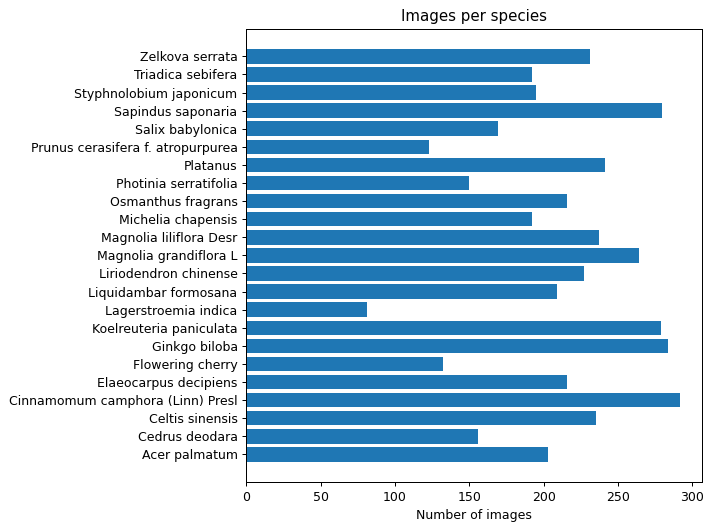

Smallest class: Lagerstroemia indica 81 | Biggest class: Cinnamomum camphora (Linn) Presl 292


In [7]:
# Class balance
counts = pd.Series(all_species).value_counts().sort_index()

plt.figure(figsize=(8, 6))
plt.barh(counts.index, counts.values)
plt.xlabel("Number of images"); plt.title("Images per species")
plt.tight_layout(); plt.show()

print("Smallest class:", counts.idxmin(), counts.min(), "| Biggest class:", counts.idxmax(), counts.max())

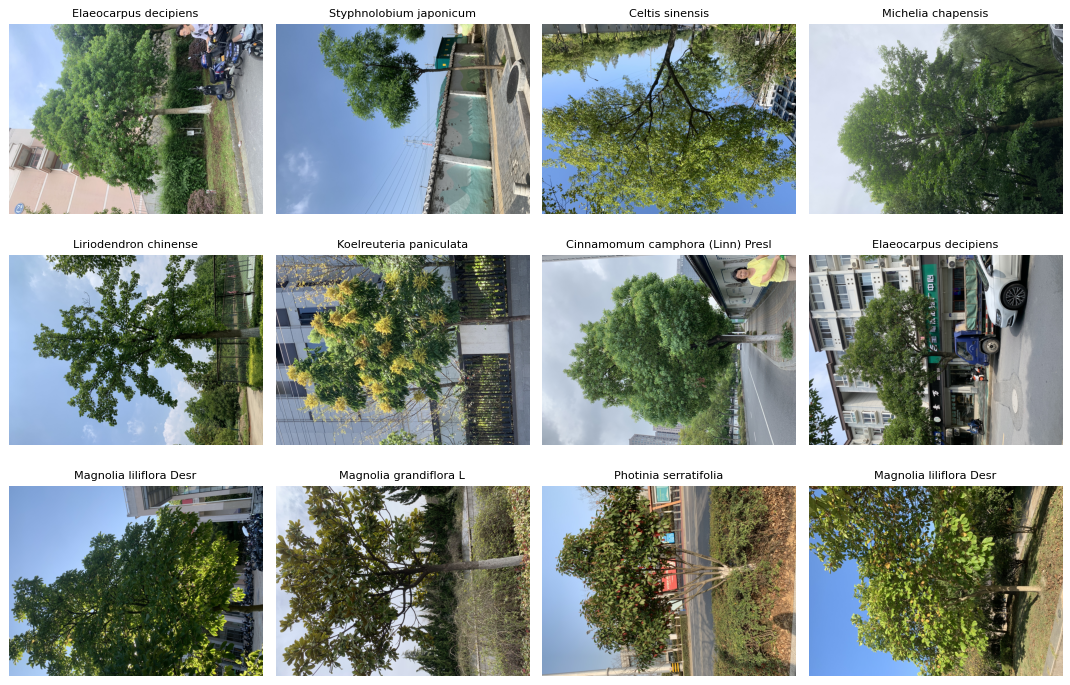

In [8]:
# Some random photos (exif_transpose = rotate the photo the way the phone meant it)
fig, axs = plt.subplots(3, 4, figsize=(12, 8))
for ax, i in zip(axs.ravel(), random.sample(range(len(all_paths)), 12)):
    ax.imshow(ImageOps.exif_transpose(Image.open(all_paths[i])))
    ax.set_title(all_species[i], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Pixels & Image Tensors
**Key ideas**
- The tree photos are **RGB**: `(H, W, 3)` in PIL/NumPy, `(3, H, W)` as a PyTorch tensor.
- They are much bigger than MNIST (28×28), so image size matters a lot for speed.

In [9]:
# Load one sample and inspect it like we did with MNIST
img = ImageOps.exif_transpose(Image.open(all_paths[0])).convert("RGB")
x = T.ToTensor()(img)
print("PIL size (W, H):", img.size)
print("Tensor shape:", x.shape, "| dtype:", x.dtype, "| min/max:", float(x.min()), float(x.max()))

# Why not the DeepMLP from the lecture? Flattening even a 224x224 crop gives a huge input vector,
# and an MLP loses the spatial structure -> we use CNNs (ResNet) instead.
print("Flattened 224x224 RGB input size:", 3 * 224 * 224, "(MNIST was", 28 * 28, ")")

PIL size (W, H): (1600, 1200)
Tensor shape: torch.Size([3, 1200, 1600]) | dtype: torch.float32 | min/max: 0.0 1.0
Flattened 224x224 RGB input size: 150528 (MNIST was 784 )


In [10]:
# Check sizes of a random sample of the original photos
sizes = [Image.open(p).size for p in random.sample(all_paths, 50)]
print("Examples:", sizes[:8])
print("Width range:", min(s[0] for s in sizes), "-", max(s[0] for s in sizes),
      "| Height range:", min(s[1] for s in sizes), "-", max(s[1] for s in sizes))

Examples: [(1600, 1200), (1600, 1200), (1600, 1200), (1600, 1200), (1600, 1200), (1600, 1200), (1600, 1200), (1600, 1200)]
Width range: 1200 - 1600 | Height range: 1200 - 1600


## 3. What is Image Classification here?
- Input: RGB image tensor `[3, 224, 224]` → Output: one of **K = 23** tree species.
- Model outputs **23 logits**. We train with **CrossEntropyLoss**.
- Metrics: **accuracy**, **precision / recall / F1** (macro average, every species counts the same),
  **confusion matrix**, and **top-n (n-best)** accuracy.

## 4. Preprocessing: resize once
**Why?**
- The originals are big phone photos. Decoding them every epoch is much slower than the training itself.
- The network only sees 224×224 crops, and the tutorial pipeline starts with `Resize(256)`.
  So we resize every photo **once** so that the shorter side is 256 px (aspect ratio kept) → no information lost for training.
- `ImageOps.exif_transpose` fixes photos that the phone saved sideways.

In [11]:
SMALL_DIR = "data_small"
shrink = T.Resize(256)          # shorter side -> 256 px, keeps the aspect ratio

paths, species = [], []
start = time.time()
for i, (p, sp) in enumerate(zip(all_paths, all_species)):
    out_dir = os.path.join(SMALL_DIR, sp)
    os.makedirs(out_dir, exist_ok=True)
    out_path = os.path.join(out_dir, f"{i}.jpg")
    if not os.path.exists(out_path):
        try:
            im = ImageOps.exif_transpose(Image.open(p)).convert("RGB")
            shrink(im).save(out_path, quality=95)
        except Exception as e:
            print("Skipped broken image:", p, e)
            continue
    paths.append(out_path)
    species.append(sp)

print(f"{len(paths)} images ready in {time.time() - start:.0f} s")

4804 images ready in 224 s


### Train / validation / test split

In [12]:
labels = [class_names.index(s) for s in species]

# 70% train, 15% validation, 15% test; stratify keeps the class proportions equal in all splits
train_p, temp_p, train_y, temp_y = train_test_split(paths, labels, test_size=0.30,
                                                    stratify=labels, random_state=SEED)
val_p, test_p, val_y, test_y = train_test_split(temp_p, temp_y, test_size=0.50,
                                                stratify=temp_y, random_state=SEED)

print("train:", len(train_p), "| val:", len(val_p), "| test:", len(test_p))

train: 3362 | val: 721 | test: 721


## 5. Transforms & Augmentation
**Why transforms?**
- Put images into the right format/range (`ToTensor`).
- Standardize scale per channel (`Normalize`) — here with **ImageNet mean/std**, because the pretrained
  ResNet weights were trained with those values (so we don't need `compute_mean_std` like with MNIST).
- Ensure common sizes for batching (`Resize` / `CenterCrop` / `RandomResizedCrop`).
- Increase diversity with randomness (augmentations) → less overfitting.

### Scaling & Aspect Ratios — Visual (tree photo)

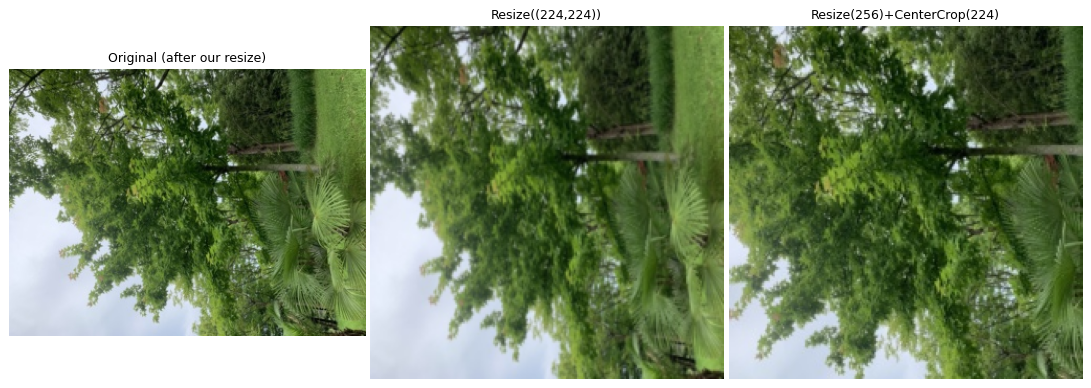

In [13]:
img = Image.open(train_p[0]).convert("RGB")

# Direct resize to (224,224) -> distorts the tree if the photo is not square
distort = T.Resize((224, 224))
# Resize smallest side to 256, then take a centered 224x224 crop -> keeps aspect ratio (used for val/test)
preserve = T.Compose([T.Resize(256), T.CenterCrop(224)])

variants = [
    ("Original (after our resize)", img),
    ("Resize((224,224))", distort(img)),
    ("Resize(256)+CenterCrop(224)", preserve(img)),
]

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, im) in zip(axs, variants):
    ax.imshow(im); ax.set_title(name, fontsize=10); ax.axis("off")
plt.tight_layout(pad=0.2); plt.show()

### Augmentation — Visual Examples

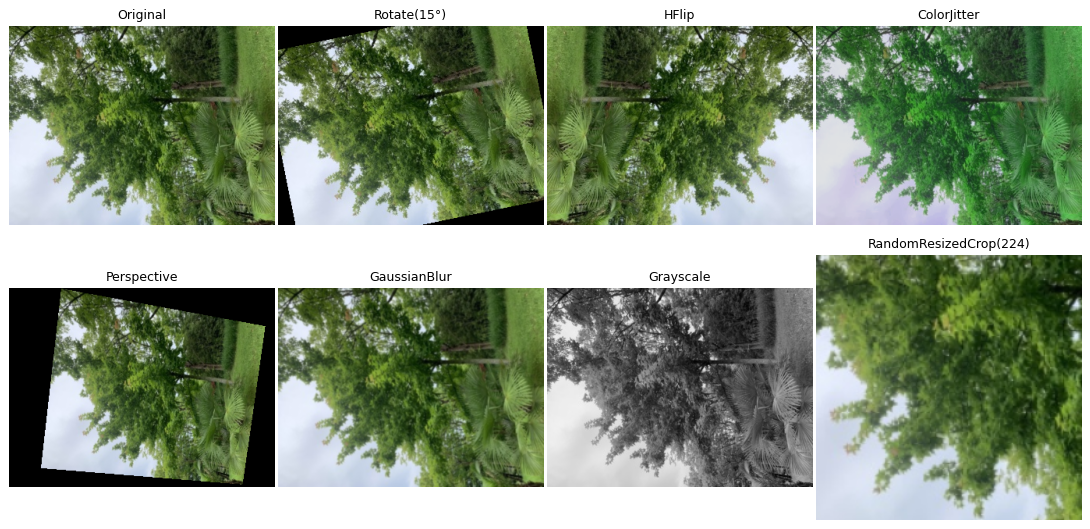

In [14]:
augs = [
    ("Rotate(15°)", T.RandomRotation(15)),
    ("HFlip", T.RandomHorizontalFlip(p=1.0)),
    ("ColorJitter", T.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1)),
    ("Perspective", T.RandomPerspective(distortion_scale=0.4, p=1.0)),
    ("GaussianBlur", T.GaussianBlur(kernel_size=9, sigma=(0.1, 2.0))),
    ("Grayscale", T.RandomGrayscale(p=1.0)),
    ("RandomResizedCrop(224)", T.RandomResizedCrop(224)),   # used in the tutorial
]

fig, axs = plt.subplots(2, 4, figsize=(12, 6))
axs = axs.ravel()
axs[0].imshow(img); axs[0].set_title("Original", fontsize=10); axs[0].axis("off")
for i, (name, aug) in enumerate(augs, start=1):
    axs[i].imshow(aug(img)); axs[i].set_title(name, fontsize=10); axs[i].axis("off")
plt.tight_layout(pad=0.3); plt.show()

### Transform recipes used in round 1
Same as in the PyTorch transfer learning tutorial: random crop + horizontal flip for training,
resize + center crop for validation and test (no randomness there).

In [15]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tfms = T.Compose([
    T.RandomResizedCrop(224),          # random part of the image, resized to 224x224
    T.RandomHorizontalFlip(),          # trees look the same mirrored
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

val_tfms = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_tfms, val_tfms

(Compose(
     RandomResizedCrop(size=(224, 224), scale=(0.08, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
     RandomHorizontalFlip(p=0.5)
     ToTensor()
     Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
 ),
 Compose(
     Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
     CenterCrop(size=(224, 224))
     ToTensor()
     Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
 ))

### Dataset & DataLoaders

In [16]:
class TreeDataset(Dataset):
    # Simple dataset: list of image paths + list of labels
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = paths, labels, transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]


# pin_memory=True if using GPU -> speeds up data transfer
pin = True if device.type == "cuda" else False

def make_loaders(train_transform, batch_size=32):
    # val and test always use val_tfms, only the training transform changes between rounds
    return {
        "train": DataLoader(TreeDataset(train_p, train_y, train_transform), batch_size=batch_size,
                            shuffle=True, num_workers=NUM_WORKERS, pin_memory=pin),
        "val":   DataLoader(TreeDataset(val_p, val_y, val_tfms), batch_size=64,
                            shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin),
        "test":  DataLoader(TreeDataset(test_p, test_y, val_tfms), batch_size=64,
                            shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin),
    }

loaders = make_loaders(train_tfms)

# Sanity check: fetch one batch
xb, yb = next(iter(loaders["train"]))
xb.shape, yb.shape   # Expected: (32, 3, 224, 224), (32,)

(torch.Size([32, 3, 224, 224]), torch.Size([32]))

## 6. Modeling: Pretrained ResNets (Transfer Learning)

| | **ResNet18** | **ResNet50** |
|---|---|---|
| Depth | 18 layers | 50 layers |
| Block type | BasicBlock (2× 3×3 conv) | Bottleneck (1×1 → 3×3 → 1×1 conv) |
| Parameters | ~11.7 M | ~25.6 M |
| Features before `fc` | 512 | 2048 |
| ImageNet top-1 (pretrained) | 69.8 % | 76.1 % |

**Transfer learning (fine-tuning):**
- Load weights pretrained on ImageNet (1000 classes) → the conv layers already know edges, textures, leaves, bark…
- Replace the last layer `fc` with a new `Linear(features → 23)`.
- Train **all** layers with a small learning rate (option 1 in the tutorial: "finetuning the ConvNet").

In [17]:
def make_model(name, num_classes=num_classes):
    # Pretrained ResNet with a new output layer for our classes
    if name == "resnet18":
        model = models.resnet18(weights="IMAGENET1K_V1")
    elif name == "resnet50":
        model = models.resnet50(weights="IMAGENET1K_V1")
    else:
        raise ValueError(name)
    model.fc = nn.Linear(model.fc.in_features, num_classes)   # 512 -> 23 or 2048 -> 23
    return model.to(device)


def count_params(model):
    return sum(p.numel() for p in model.parameters())

for name in ["resnet18", "resnet50"]:
    m = make_model(name)
    print(f"{name}: {count_params(m)/1e6:.1f} M parameters | last layer: {m.fc}")
del m

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 79.1MB/s]


resnet18: 11.2 M parameters | last layer: Linear(in_features=512, out_features=23, bias=True)
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 104MB/s]


resnet50: 23.6 M parameters | last layer: Linear(in_features=2048, out_features=23, bias=True)


### Training & Evaluation helpers
Based on the lecture helpers. Changes compared to the MNIST version:
- `denorm` / `show_batch` / `show_misclassified` work with RGB + ImageNet normalization and show species names.
- `train_epochs` also tracks **training accuracy**, uses the **StepLR** scheduler from the tutorial
  (lr × 0.1 every `step_size` epochs) and **keeps the weights of the epoch with the best validation accuracy**.
  The validation set is only used for this — the test set is only used at the very end.
- `show_confusion_matrices` is made bigger for 23 classes.

In [18]:
# ---------------- Training helpers ----------------

def denorm(x, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    # Undo ImageNet normalization for display; x has shape [H, W, 3]
    return (x * torch.tensor(std) + torch.tensor(mean)).clamp(0, 1)


def show_batch(loader, n=16, nrow=8):
    # Show a batch of sample images from a DataLoader (after transforms/augmentation)
    xb, yb = next(iter(loader))
    grid = torchvision.utils.make_grid(xb[:n], nrow=nrow, padding=2)
    plt.figure(figsize=(14, 4))
    plt.imshow(denorm(grid.permute(1, 2, 0)))
    plt.axis("off"); plt.title("Sample training batch"); plt.show()
    print("Labels:", [class_names[i] for i in yb[:n]])


def evaluate_loader(model, loader, loss_fn, device):
    # Average loss and accuracy over a loader
    model.eval()
    total, correct, running = 0, 0, 0.0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            running += loss_fn(out, yb).item() * xb.size(0)
            correct += (out.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
    return running / total, correct / total


def train_epochs(model, train_loader, val_loader, epochs=15, lr=1e-4, wd=1e-4,
                 step_size=7, label_smoothing=0.0, device="cpu"):
    # Train a model for multiple epochs, with validation at each epoch.
    # Returns the model with the BEST validation weights + history dictionary.
    ce = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    sched = lr_scheduler.StepLR(opt, step_size=step_size, gamma=0.1)   # from the transfer learning tutorial
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_wts = 0.0, copy.deepcopy(model.state_dict())
    start = time.time()

    for ep in range(1, epochs + 1):
        model.train()
        running, correct = 0.0, 0

        # Training loop
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = ce(out, yb)

            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()

            running += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
        sched.step()

        train_loss = running / len(train_loader.dataset)
        train_acc = correct / len(train_loader.dataset)
        val_loss, val_acc = evaluate_loader(model, val_loader, ce, device)

        hist["train_loss"].append(train_loss); hist["train_acc"].append(train_acc)
        hist["val_loss"].append(val_loss);     hist["val_acc"].append(val_acc)

        mark = ""
        if val_acc > best_acc:   # keep the best epoch
            best_acc, best_wts, mark = val_acc, copy.deepcopy(model.state_dict()), "  *best*"
        print(f"Epoch {ep:2d} | train={train_loss:.4f} acc={train_acc:.4f} | "
              f"val={val_loss:.4f} acc={val_acc:.4f}{mark}")

    print(f"Training time: {(time.time() - start) / 60:.1f} min | best val acc: {best_acc:.4f}")
    model.load_state_dict(best_wts)
    return model, hist


def plot_curves(hist, title=""):
    # Loss and accuracy curves for train and validation
    epochs = range(1, len(hist["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
    ax1.plot(epochs, hist["train_loss"], label="train_loss")
    ax1.plot(epochs, hist["val_loss"], label="val_loss")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.set_title(title + " loss")
    ax1.legend(); ax1.grid(True, alpha=0.3)
    ax2.plot(epochs, hist["train_acc"], label="train_acc")
    ax2.plot(epochs, hist["val_acc"], label="val_acc")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy"); ax2.set_ylim(0, 1); ax2.set_title(title + " accuracy")
    ax2.legend(); ax2.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

In [19]:
# ---------------- Evaluation helpers ----------------

def get_predictions(model, loader, device="cpu"):
    # True labels, predicted labels and softmax probabilities (probabilities are needed for n-best)
    model.eval(); ys, probs = [], []
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb.to(device))
            probs.append(torch.softmax(out, dim=1).cpu())
            ys.append(yb)
    probs = torch.cat(probs).numpy()
    y_true = torch.cat(ys).numpy()
    return y_true, probs.argmax(1), probs


results = {}   # test results of every model, used for the comparisons

def test_model(model, name, loader):
    # Accuracy + macro precision / recall / F1 on the test set, stored in `results`
    y_true, y_pred, probs = get_predictions(model, loader, device)
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    results[name] = dict(y_true=y_true, y_pred=y_pred, probs=probs,
                         accuracy=acc, precision=prec, recall=rec, f1=f1)
    print(f"{name:12s} | accuracy {acc:.4f} | precision {prec:.4f} | recall {rec:.4f} | F1 {f1:.4f}")


def show_confusion_matrices(name, labels=class_names, min_pct_annot=0.05, hide_diag_on_norm=False):
    # Side-by-side confusion matrices: raw counts and normalized (row-wise), for a tested model
    y_true, y_pred = results[name]["y_true"], results[name]["y_pred"]
    n = len(labels)
    cm_raw  = confusion_matrix(y_true, y_pred, labels=range(n))
    cm_norm = confusion_matrix(y_true, y_pred, labels=range(n), normalize="true")

    fig, axes = plt.subplots(1, 2, figsize=(24, 10))

    ann_raw = np.where(cm_raw == 0, "", cm_raw.astype(int))  # hide zeros
    sns.heatmap(cm_raw, ax=axes[0], annot=ann_raw, fmt="", cmap="Blues", cbar=False, square=True,
                linewidths=.5, linecolor="white", annot_kws={"size": 7},
                xticklabels=labels, yticklabels=labels)
    axes[0].set_title(f"{name} — confusion matrix (counts)")

    ann_norm = np.where(cm_norm >= min_pct_annot, np.round(cm_norm * 100).astype(int).astype(str), "")
    mask = np.eye(n, dtype=bool) if hide_diag_on_norm else None
    sns.heatmap(cm_norm, ax=axes[1], annot=ann_norm, fmt="", cmap="Blues", vmin=0, vmax=1, square=True,
                linewidths=.5, linecolor="white", mask=mask, annot_kws={"size": 7},
                xticklabels=labels, yticklabels=labels)
    axes[1].set_title(f"{name} — normalized % (≥{int(min_pct_annot*100)}% annotated)")

    for ax in axes:
        ax.set_xlabel("Pred"); ax.set_ylabel("True")
        ax.tick_params(axis="x", labelrotation=90, labelsize=8)
        ax.tick_params(axis="y", labelrotation=0, labelsize=8)
    plt.tight_layout(); plt.show()


def most_confused(name, top=10):
    # The most common (true -> predicted) mistakes
    cm = confusion_matrix(results[name]["y_true"], results[name]["y_pred"], labels=range(num_classes))
    np.fill_diagonal(cm, 0)
    pairs = [(cm[i, j], class_names[i], class_names[j])
             for i in range(num_classes) for j in range(num_classes) if cm[i, j] > 0]
    pairs.sort(reverse=True)
    print(f"--- {name}: most common errors (true → predicted) ---")
    for c, t, p in pairs[:top]:
        print(f"{c:3d}   {t}  →  {p}")


def show_misclassified(name, k=20, nrow=5):
    # Grid of k random wrong test predictions (original resized photo, true / predicted + confidence)
    r = results[name]
    wrong = np.where(r["y_true"] != r["y_pred"])[0]
    print(f"{name}: {len(wrong)} wrong out of {len(r['y_true'])} test images")
    pick = random.sample(list(wrong), min(k, len(wrong)))
    fig, axs = plt.subplots((len(pick) + nrow - 1) // nrow, nrow, figsize=(16, 3.6 * ((len(pick) + nrow - 1) // nrow)))
    for ax in np.atleast_1d(axs).ravel():
        ax.axis("off")
    for ax, i in zip(np.atleast_1d(axs).ravel(), pick):
        ax.imshow(Image.open(test_p[i]))
        ax.set_title(f"T: {class_names[r['y_true'][i]]}\nP: {class_names[r['y_pred'][i]]} ({r['probs'][i].max():.2f})",
                     fontsize=8, color="red")
    plt.tight_layout(); plt.show()


def top_n_accuracy(probs, y_true, n):
    # Correct if the true class is among the n highest probabilities
    top_n = np.argsort(probs, axis=1)[:, -n:]
    return np.mean([y_true[i] in top_n[i] for i in range(len(y_true))])

In [ ]:
# Quick sanity check: visualize a batch of training images (after augmentation)
show_batch(loaders["train"])

## 7. Training round 1 — baseline
Same settings for both models so the comparison is fair:
- Adam, learning rate 1e-4 (small because the weights are already pretrained), weight decay 1e-4
- StepLR: learning rate × 0.1 every 7 epochs
- 15 epochs, batch size 32
- The weights from the epoch with the best **validation** accuracy are kept

### 7.1 ResNet18

In [20]:
EPOCHS = 15

model18 = make_model("resnet18")
model18, hist18 = train_epochs(model18, loaders["train"], loaders["val"],
                               epochs=EPOCHS, lr=1e-4, wd=1e-4, step_size=7, device=device)
torch.save(model18.state_dict(), os.path.join(SAVE_DIR, "resnet18_round1.pth"))

Epoch  1 | train=2.1008 acc=0.4143 | val=1.1339 acc=0.6796  *best*
Epoch  2 | train=1.1182 acc=0.6966 | val=0.9335 acc=0.7198  *best*
Epoch  3 | train=0.8116 acc=0.7650 | val=0.5843 acc=0.8294  *best*
Epoch  4 | train=0.6802 acc=0.8052 | val=0.6287 acc=0.8141
Epoch  5 | train=0.5499 acc=0.8483 | val=0.5093 acc=0.8405  *best*
Epoch  6 | train=0.5152 acc=0.8498 | val=0.5132 acc=0.8558  *best*
Epoch  7 | train=0.4881 acc=0.8647 | val=0.6177 acc=0.8308
Epoch  8 | train=0.3867 acc=0.8941 | val=0.4916 acc=0.8488
Epoch  9 | train=0.3462 acc=0.9078 | val=0.4163 acc=0.8738  *best*
Epoch 10 | train=0.3235 acc=0.9158 | val=0.4320 acc=0.8724
Epoch 11 | train=0.3209 acc=0.9173 | val=0.3755 acc=0.8863  *best*
Epoch 12 | train=0.3262 acc=0.9173 | val=0.4749 acc=0.8641
Epoch 13 | train=0.3085 acc=0.9155 | val=0.4058 acc=0.8766
Epoch 14 | train=0.3072 acc=0.9170 | val=0.3778 acc=0.8890  *best*
Epoch 15 | train=0.2975 acc=0.9224 | val=0.4296 acc=0.8752
Training time: 4.6 min | best val acc: 0.8890


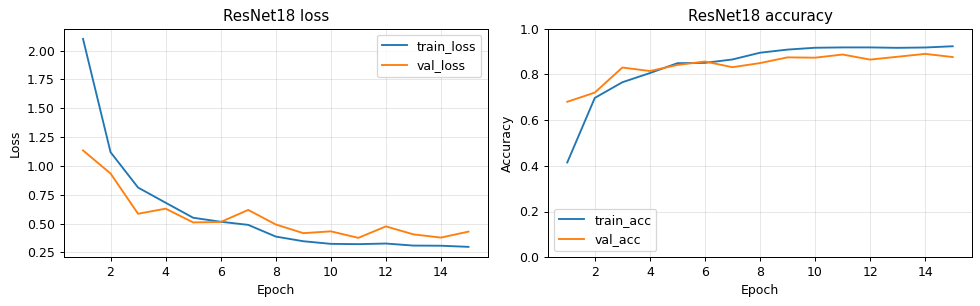

In [21]:
plot_curves(hist18, "ResNet18")

### 7.2 ResNet50

In [22]:
model50 = make_model("resnet50")
model50, hist50 = train_epochs(model50, loaders["train"], loaders["val"],
                               epochs=EPOCHS, lr=1e-4, wd=1e-4, step_size=7, device=device)
torch.save(model50.state_dict(), os.path.join(SAVE_DIR, "resnet50_round1.pth"))

Epoch  1 | train=1.9759 acc=0.4462 | val=1.0658 acc=0.6907  *best*
Epoch  2 | train=0.9544 acc=0.7338 | val=0.9685 acc=0.7240  *best*
Epoch  3 | train=0.7041 acc=0.7942 | val=0.6313 acc=0.8086  *best*
Epoch  4 | train=0.6142 acc=0.8218 | val=0.6096 acc=0.8072
Epoch  5 | train=0.5079 acc=0.8551 | val=0.5711 acc=0.8419  *best*
Epoch  6 | train=0.4611 acc=0.8629 | val=0.6688 acc=0.8086
Epoch  7 | train=0.4703 acc=0.8617 | val=0.3981 acc=0.8890  *best*
Epoch  8 | train=0.3318 acc=0.9036 | val=0.3830 acc=0.9015  *best*
Epoch  9 | train=0.2646 acc=0.9250 | val=0.3227 acc=0.9140  *best*
Epoch 10 | train=0.2408 acc=0.9334 | val=0.3574 acc=0.9057
Epoch 11 | train=0.2345 acc=0.9363 | val=0.3490 acc=0.9001
Epoch 12 | train=0.2231 acc=0.9381 | val=0.3362 acc=0.9209  *best*
Epoch 13 | train=0.2091 acc=0.9438 | val=0.3130 acc=0.9223  *best*
Epoch 14 | train=0.2014 acc=0.9468 | val=0.3106 acc=0.9251  *best*
Epoch 15 | train=0.2164 acc=0.9411 | val=0.3400 acc=0.9043
Training time: 10.3 min | best val 

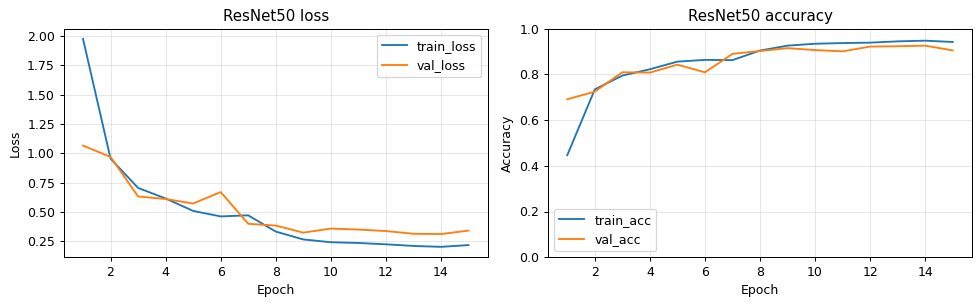

In [23]:
plot_curves(hist50, "ResNet50")

**Training observations:** ResNet50 learned quite fast during the first 7 epochs, and after the learning rate dropped at epoch 7, the curves flattened out nicely[cite: 1, 7]. Validation accuracy stopped improving much around epoch 8 to 10, staying around 91–92 %[cite: 7]. The gap between training and validation accuracy is pretty small (only a few percent), so there is no big overfitting problem[cite: 7]. ResNet50 had slightly better accuracy than ResNet18, but it took longer to train because it has way more parameters[cite: 1, 7].

## 8. Testing on the test set
The test set (15 %) was not used during training or model selection.
Precision, recall and F1 are **macro averages** (computed per species, then averaged).

In [24]:
test_model(model18, "ResNet18", loaders["test"])
test_model(model50, "ResNet50", loaders["test"])

ResNet18     | accuracy 0.8890 | precision 0.9058 | recall 0.8918 | F1 0.8937
ResNet50     | accuracy 0.9057 | precision 0.9179 | recall 0.9048 | F1 0.9072


Per-species precision, recall and F1:

In [25]:
for name in ["ResNet18", "ResNet50"]:
    print("=" * 25, name, "=" * 25)
    print(classification_report(results[name]["y_true"], results[name]["y_pred"],
                                labels=range(num_classes), target_names=class_names, digits=3, zero_division=0))

========================= ResNet18 =========================
                                   precision    recall  f1-score   support

                    Acer palmatum      0.848     0.933     0.889        30
                   Cedrus deodara      1.000     0.958     0.979        24
                  Celtis sinensis      0.846     0.943     0.892        35
 Cinnamomum camphora (Linn) Presl      0.915     0.977     0.945        44
            Elaeocarpus decipiens      0.738     0.969     0.838        32
                 Flowering cherry      0.889     0.800     0.842        20
                    Ginkgo biloba      0.764     0.977     0.857        43
          Koelreuteria paniculata      1.000     0.762     0.865        42
             Lagerstroemia indica      1.000     0.917     0.957        12
            Liquidambar formosana      0.893     0.781     0.833        32
            Liriodendron chinense      0.705     0.912     0.795        34
           Magnolia grandiflora L     

### Confusion matrices
Rows = true species, columns = predicted species. Everything outside the diagonal is an error.

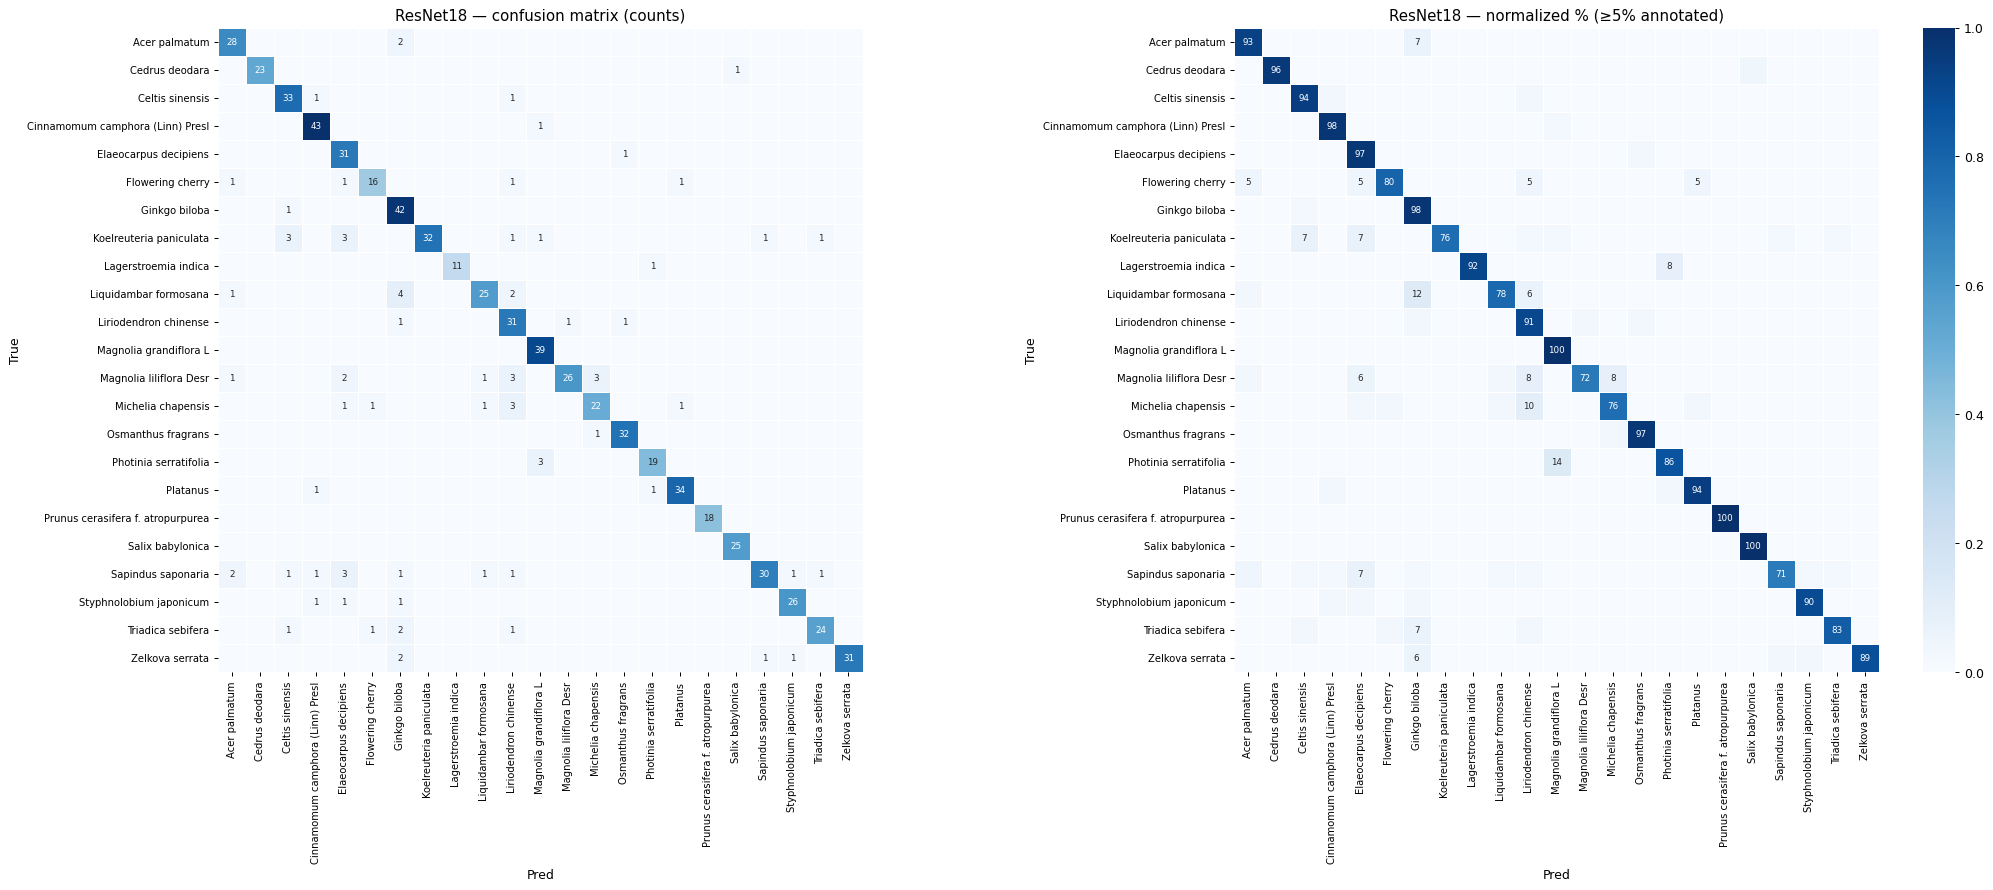

In [26]:
show_confusion_matrices("ResNet18")

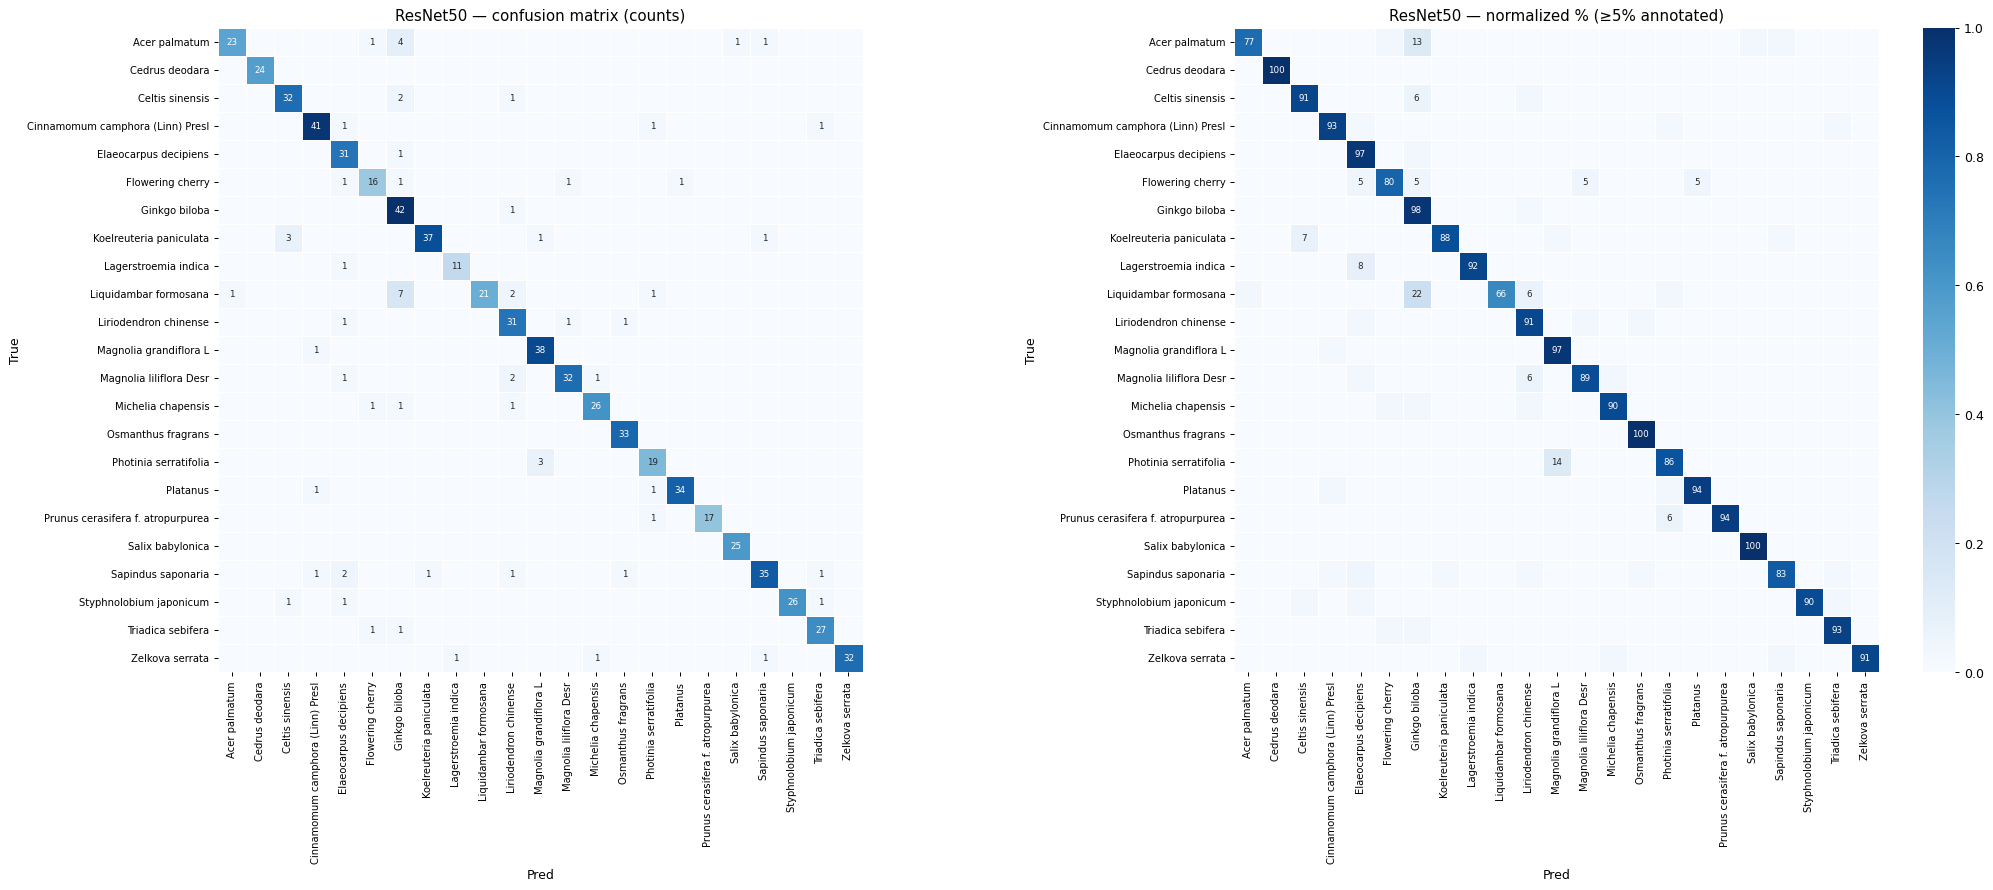

In [27]:
show_confusion_matrices("ResNet50")

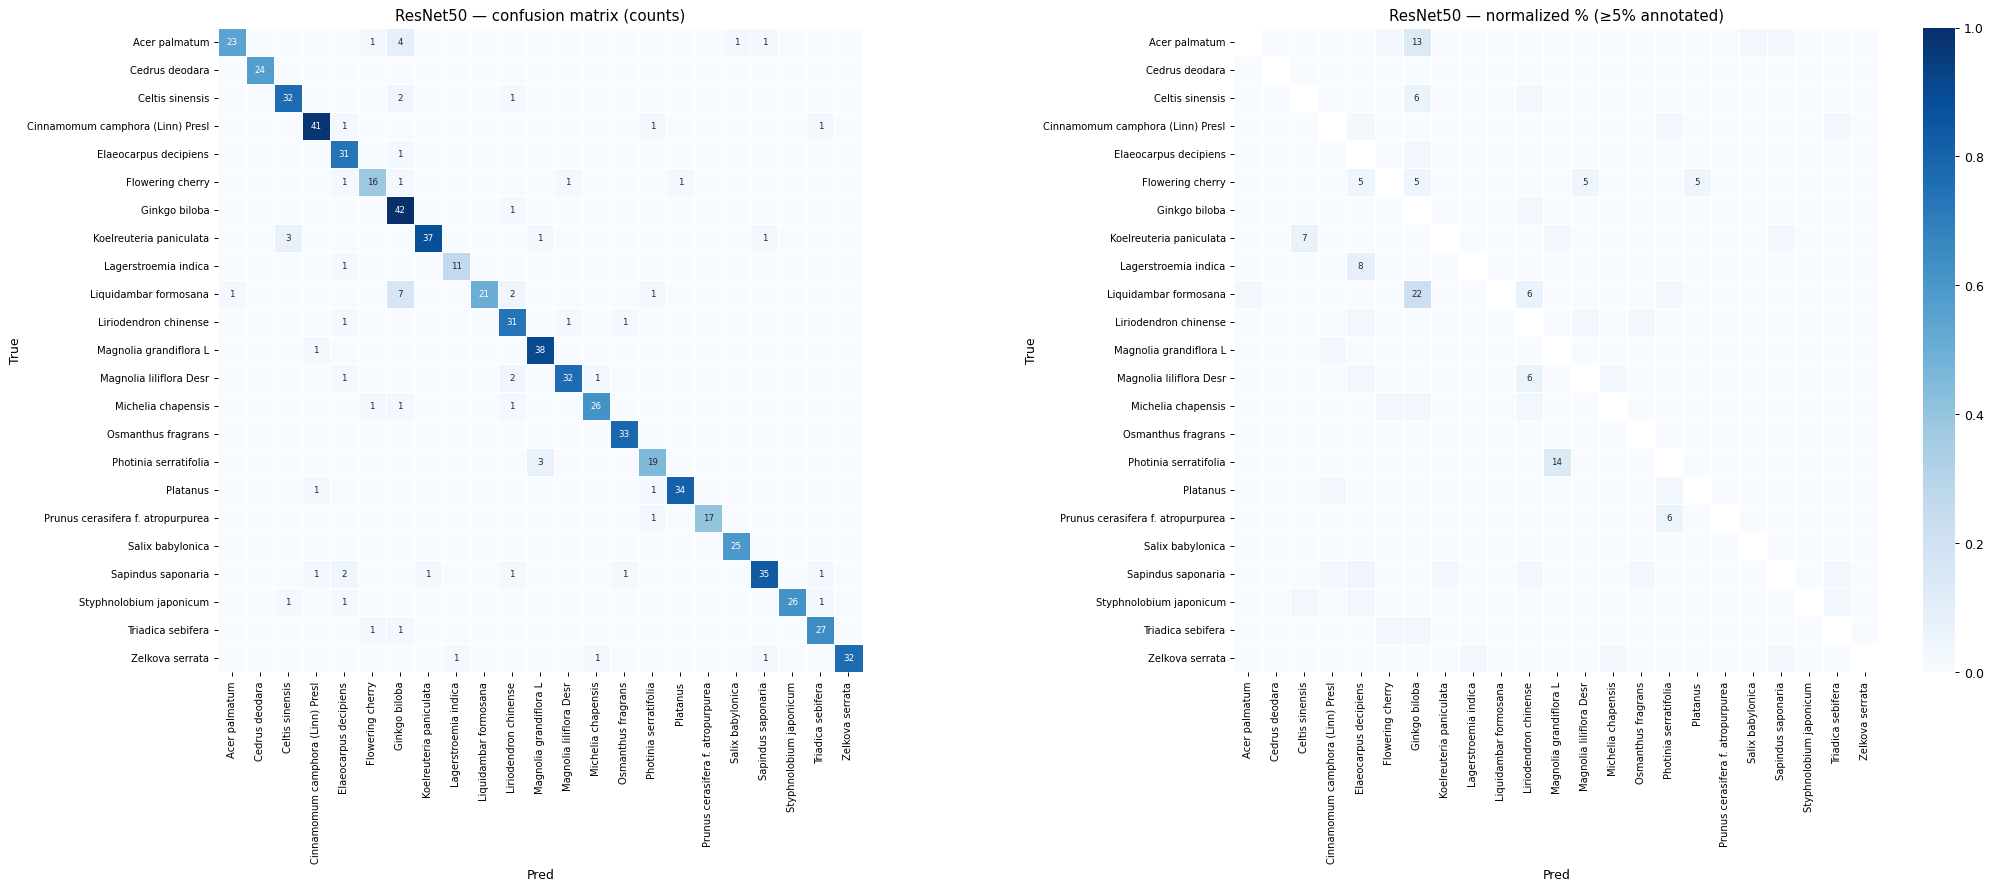

In [28]:
# To spotlight the mistakes, hide the diagonal on the normalized plot
show_confusion_matrices("ResNet50", hide_diag_on_norm=True)

## 9. N-best (top-n) results
A prediction is counted correct if the true species is among the **n most probable** species.
n = 1 is normal accuracy; when n grows, both models go towards 100 %.





In [29]:
MAX_N = 10
ns = list(range(1, MAX_N + 1))

nbest = {name: [top_n_accuracy(results[name]["probs"], results[name]["y_true"], n) for n in ns]
         for name in ["ResNet18", "ResNet50"]}

nbest_df = pd.DataFrame(nbest, index=pd.Index(ns, name="n")) * 100
nbest_df["difference (50 - 18)"] = nbest_df["ResNet50"] - nbest_df["ResNet18"]
nbest_df.round(2)

,ResNet18,ResNet50,difference (50 - 18)
n,,,
1,88.90,90.57,1.66
2,95.28,96.39,1.11
3,97.36,98.20,0.83
4,98.06,99.03,0.97
5,98.89,99.17,0.28
6,99.31,99.31,0.00
7,99.31,99.45,0.14
8,99.31,99.72,0.42
9,99.58,99.72,0.14


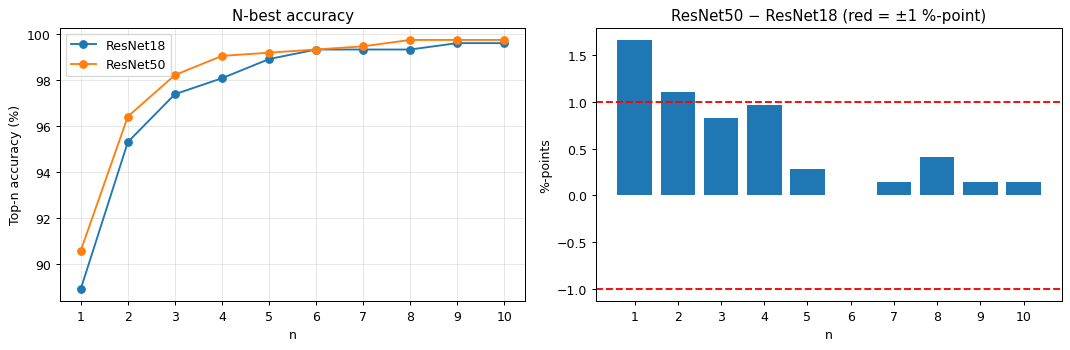

n values where the models differ by at least 1 %-point: [1, 2]


In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for name in ["ResNet18", "ResNet50"]:
    ax1.plot(ns, nbest_df[name], marker="o", label=name)
ax1.set_xlabel("n"); ax1.set_ylabel("Top-n accuracy (%)"); ax1.set_title("N-best accuracy")
ax1.set_xticks(ns); ax1.grid(True, alpha=0.3); ax1.legend()

ax2.bar(ns, nbest_df["difference (50 - 18)"])
ax2.axhline(1, color="red", ls="--"); ax2.axhline(-1, color="red", ls="--")
ax2.set_xlabel("n"); ax2.set_ylabel("%-points"); ax2.set_title("ResNet50 − ResNet18 (red = ±1 %-point)")
ax2.set_xticks(ns)
plt.tight_layout(); plt.show()

separated = [n for n in ns if abs(nbest_df.loc[n, "difference (50 - 18)"]) >= 1.0]
print("n values where the models differ by at least 1 %-point:", separated)

**N-best finding:** **N-best finding:** At n = 1 ResNet50 is 1.7 %-points better than ResNet18. The difference stays over 1 %-point up to n = 2; after that (starting from n = 3), the difference drops below the 1 %-point threshold, and both models achieve over 97 % top-n accuracy. Therefore, n-best does not meaningfully separate the models beyond n = 2.

## 10. Error analysis
Which species get mixed up, and what do the wrong images look like?
TIP (from the lecture): look for **systematic** errors — they show dataset challenges or model weaknesses.

In [31]:
most_confused("ResNet18")
most_confused("ResNet50")

--- ResNet18: most common errors (true → predicted) ---
  4   Liquidambar formosana  →  Ginkgo biloba
  3   Sapindus saponaria  →  Elaeocarpus decipiens
  3   Photinia serratifolia  →  Magnolia grandiflora L
  3   Michelia chapensis  →  Liriodendron chinense
  3   Magnolia liliflora Desr  →  Michelia chapensis
  3   Magnolia liliflora Desr  →  Liriodendron chinense
  3   Koelreuteria paniculata  →  Elaeocarpus decipiens
  3   Koelreuteria paniculata  →  Celtis sinensis
  2   Zelkova serrata  →  Ginkgo biloba
  2   Triadica sebifera  →  Ginkgo biloba
--- ResNet50: most common errors (true → predicted) ---
  7   Liquidambar formosana  →  Ginkgo biloba
  4   Acer palmatum  →  Ginkgo biloba
  3   Photinia serratifolia  →  Magnolia grandiflora L
  3   Koelreuteria paniculata  →  Celtis sinensis
  2   Sapindus saponaria  →  Elaeocarpus decipiens
  2   Magnolia liliflora Desr  →  Liriodendron chinense
  2   Liquidambar formosana  →  Liriodendron chinense
  2   Celtis sinensis  →  Ginkgo bilob

In [32]:
show_misclassified("ResNet50", k=20)

Output hidden; open in https://colab.research.google.com to view.

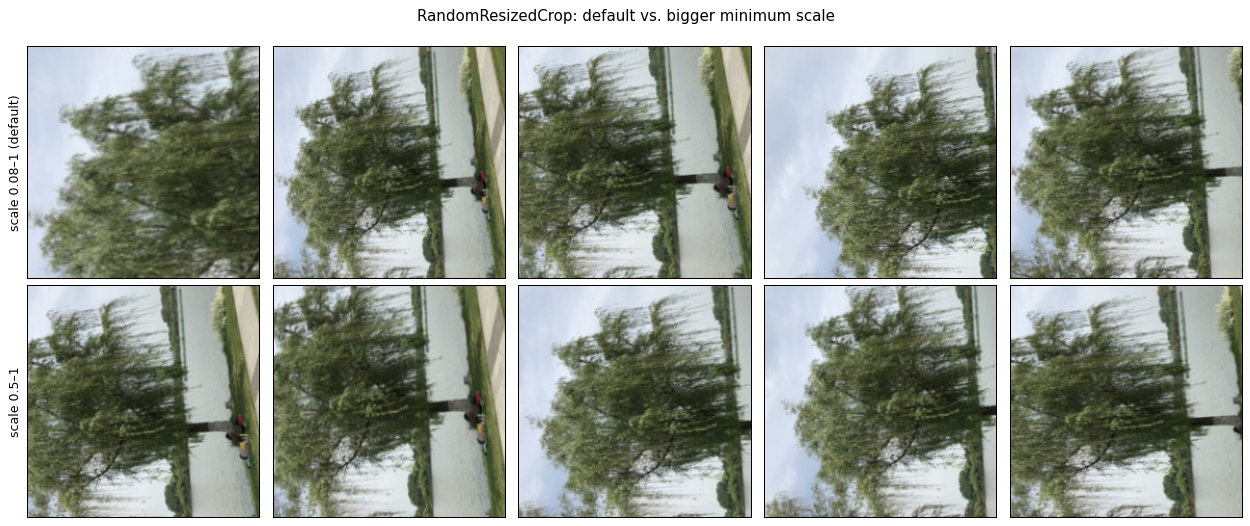

In [33]:
# How much of the tree does RandomResizedCrop keep? Default scale = 8%-100% of the image area.
img = Image.open(train_p[1]).convert("RGB")
fig, axs = plt.subplots(2, 5, figsize=(14, 6))
for j in range(5):
    axs[0, j].imshow(T.RandomResizedCrop(224)(img))
    axs[1, j].imshow(T.RandomResizedCrop(224, scale=(0.5, 1.0))(img))
    axs[0, j].set_xticks([]); axs[0, j].set_yticks([]); axs[1, j].set_xticks([]); axs[1, j].set_yticks([])
axs[0, 0].set_ylabel("scale 0.08–1 (default)"); axs[1, 0].set_ylabel("scale 0.5–1")
plt.suptitle("RandomResizedCrop: default vs. bigger minimum scale"); plt.tight_layout(); plt.show()

**What was noticed**
- Some species look very similar (same leaf/crown shape) and are confused by **both** models.
- The tree is often **small** in the photo, or there are several trees, buildings, cars, people.
  The default `RandomResizedCrop` can cut out a piece with only sky or road, so the model learns from wrong crops.
- Wrong predictions often have low confidence → the right answer is usually in the top-2/top-3 (see n-best).

**Changes for round 2**
1. `RandomResizedCrop(224, scale=(0.5, 1.0))` → crops always contain a big part of the tree
2. `ColorJitter` → robustness to light and season differences
3. small `RandomRotation(10)` → photos are not always straight
4. **label smoothing 0.1** → less over-confident between similar species
5. **20 epochs** (lr step every 8) because the stronger augmentation makes training harder

## 11. Training round 2 — improved models

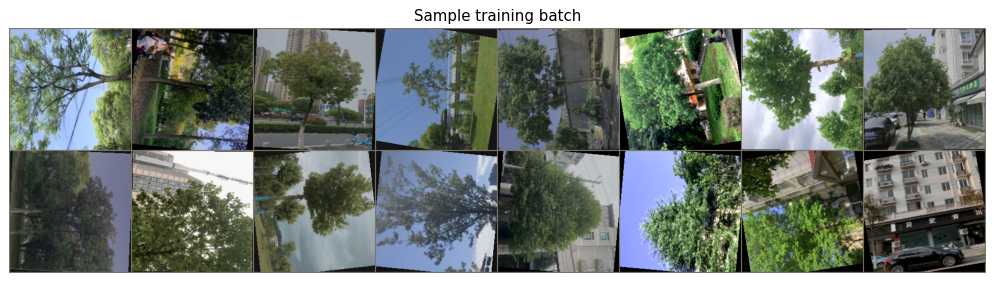

Labels: ['Koelreuteria paniculata', 'Magnolia grandiflora L', 'Cinnamomum camphora (Linn) Presl', 'Triadica sebifera', 'Sapindus saponaria', 'Elaeocarpus decipiens', 'Platanus', 'Osmanthus fragrans', 'Magnolia grandiflora L', 'Liriodendron chinense', 'Platanus', 'Zelkova serrata', 'Michelia chapensis', 'Cedrus deodara', 'Liriodendron chinense', 'Elaeocarpus decipiens']


In [34]:
train_tfms_v2 = T.Compose([
    T.RandomResizedCrop(224, scale=(0.5, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

loaders_v2 = make_loaders(train_tfms_v2)   # val/test unchanged -> results are comparable
EPOCHS_V2 = 20

show_batch(loaders_v2["train"])

### 11.1 ResNet18 v2

Epoch  1 | train=2.3583 acc=0.3864 | val=1.6981 acc=0.6047  *best*
Epoch  2 | train=1.4414 acc=0.7204 | val=1.2985 acc=0.7531  *best*
Epoch  3 | train=1.2265 acc=0.7995 | val=1.2914 acc=0.7781  *best*
Epoch  4 | train=1.0861 acc=0.8519 | val=1.2103 acc=0.8169  *best*
Epoch  5 | train=0.9849 acc=0.9001 | val=1.1139 acc=0.8294  *best*
Epoch  6 | train=0.9357 acc=0.9152 | val=1.0978 acc=0.8433  *best*
Epoch  7 | train=0.9043 acc=0.9274 | val=1.0607 acc=0.8474  *best*
Epoch  8 | train=0.8670 acc=0.9432 | val=1.0430 acc=0.8641  *best*
Epoch  9 | train=0.8098 acc=0.9679 | val=1.0251 acc=0.8641
Epoch 10 | train=0.7946 acc=0.9714 | val=1.0129 acc=0.8807  *best*
Epoch 11 | train=0.7871 acc=0.9747 | val=1.0022 acc=0.8835  *best*
Epoch 12 | train=0.7784 acc=0.9771 | val=1.0116 acc=0.8724
Epoch 13 | train=0.7717 acc=0.9804 | val=0.9904 acc=0.8849  *best*
Epoch 14 | train=0.7790 acc=0.9735 | val=1.0059 acc=0.8807
Epoch 15 | train=0.7716 acc=0.9780 | val=0.9984 acc=0.8779
Epoch 16 | train=0.7643 acc

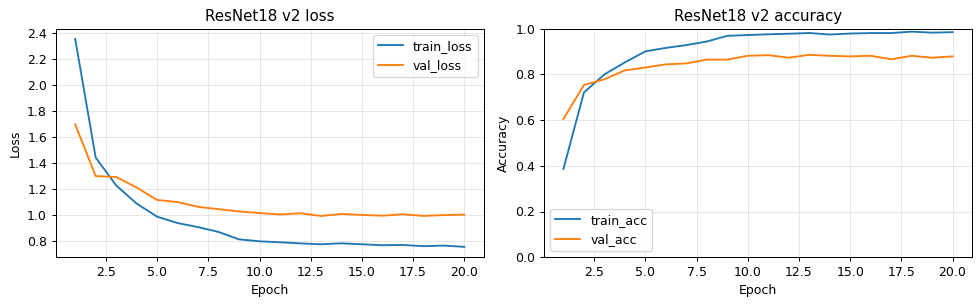

In [35]:
model18_v2 = make_model("resnet18")
model18_v2, hist18_v2 = train_epochs(model18_v2, loaders_v2["train"], loaders_v2["val"], epochs=EPOCHS_V2,
                                     lr=1e-4, wd=1e-4, step_size=8, label_smoothing=0.1, device=device)
torch.save(model18_v2.state_dict(), os.path.join(SAVE_DIR, "resnet18_round2.pth"))
plot_curves(hist18_v2, "ResNet18 v2")

### 11.2 ResNet50 v2

Epoch  1 | train=2.1234 acc=0.4640 | val=1.3854 acc=0.7198  *best*
Epoch  2 | train=1.3061 acc=0.7582 | val=1.2445 acc=0.7781  *best*
Epoch  3 | train=1.0882 acc=0.8438 | val=1.2660 acc=0.7781
Epoch  4 | train=0.9808 acc=0.8822 | val=1.1210 acc=0.8377  *best*
Epoch  5 | train=0.9240 acc=0.9081 | val=0.9962 acc=0.8877  *best*
Epoch  6 | train=0.8942 acc=0.9206 | val=0.9935 acc=0.8932  *best*
Epoch  7 | train=0.8681 acc=0.9343 | val=0.9955 acc=0.8793
Epoch  8 | train=0.8351 acc=0.9500 | val=0.9815 acc=0.8849
Epoch  9 | train=0.7648 acc=0.9717 | val=0.9171 acc=0.9098  *best*
Epoch 10 | train=0.7460 acc=0.9801 | val=0.9219 acc=0.9071
Epoch 11 | train=0.7311 acc=0.9854 | val=0.9264 acc=0.8960
Epoch 12 | train=0.7260 acc=0.9839 | val=0.9358 acc=0.9015
Epoch 13 | train=0.7172 acc=0.9881 | val=0.9010 acc=0.9071
Epoch 14 | train=0.7159 acc=0.9848 | val=0.9132 acc=0.9085
Epoch 15 | train=0.7145 acc=0.9887 | val=0.9048 acc=0.9112  *best*
Epoch 16 | train=0.7102 acc=0.9908 | val=0.9044 acc=0.9098


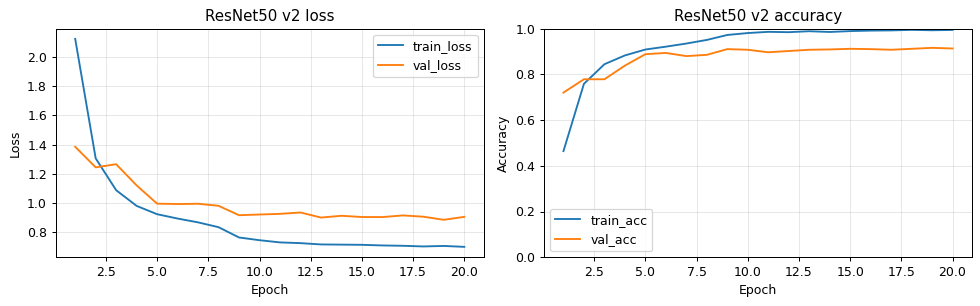

In [36]:
model50_v2 = make_model("resnet50")
model50_v2, hist50_v2 = train_epochs(model50_v2, loaders_v2["train"], loaders_v2["val"], epochs=EPOCHS_V2,
                                     lr=1e-4, wd=1e-4, step_size=8, label_smoothing=0.1, device=device)
torch.save(model50_v2.state_dict(), os.path.join(SAVE_DIR, "resnet50_round2.pth"))
plot_curves(hist50_v2, "ResNet50 v2")

### 11.3 Test results of the improved models

In [37]:
test_model(model18_v2, "ResNet18 v2", loaders_v2["test"])
test_model(model50_v2, "ResNet50 v2", loaders_v2["test"])

ResNet18 v2  | accuracy 0.8669 | precision 0.8822 | recall 0.8703 | F1 0.8687
ResNet50 v2  | accuracy 0.9098 | precision 0.9194 | recall 0.9108 | F1 0.9122


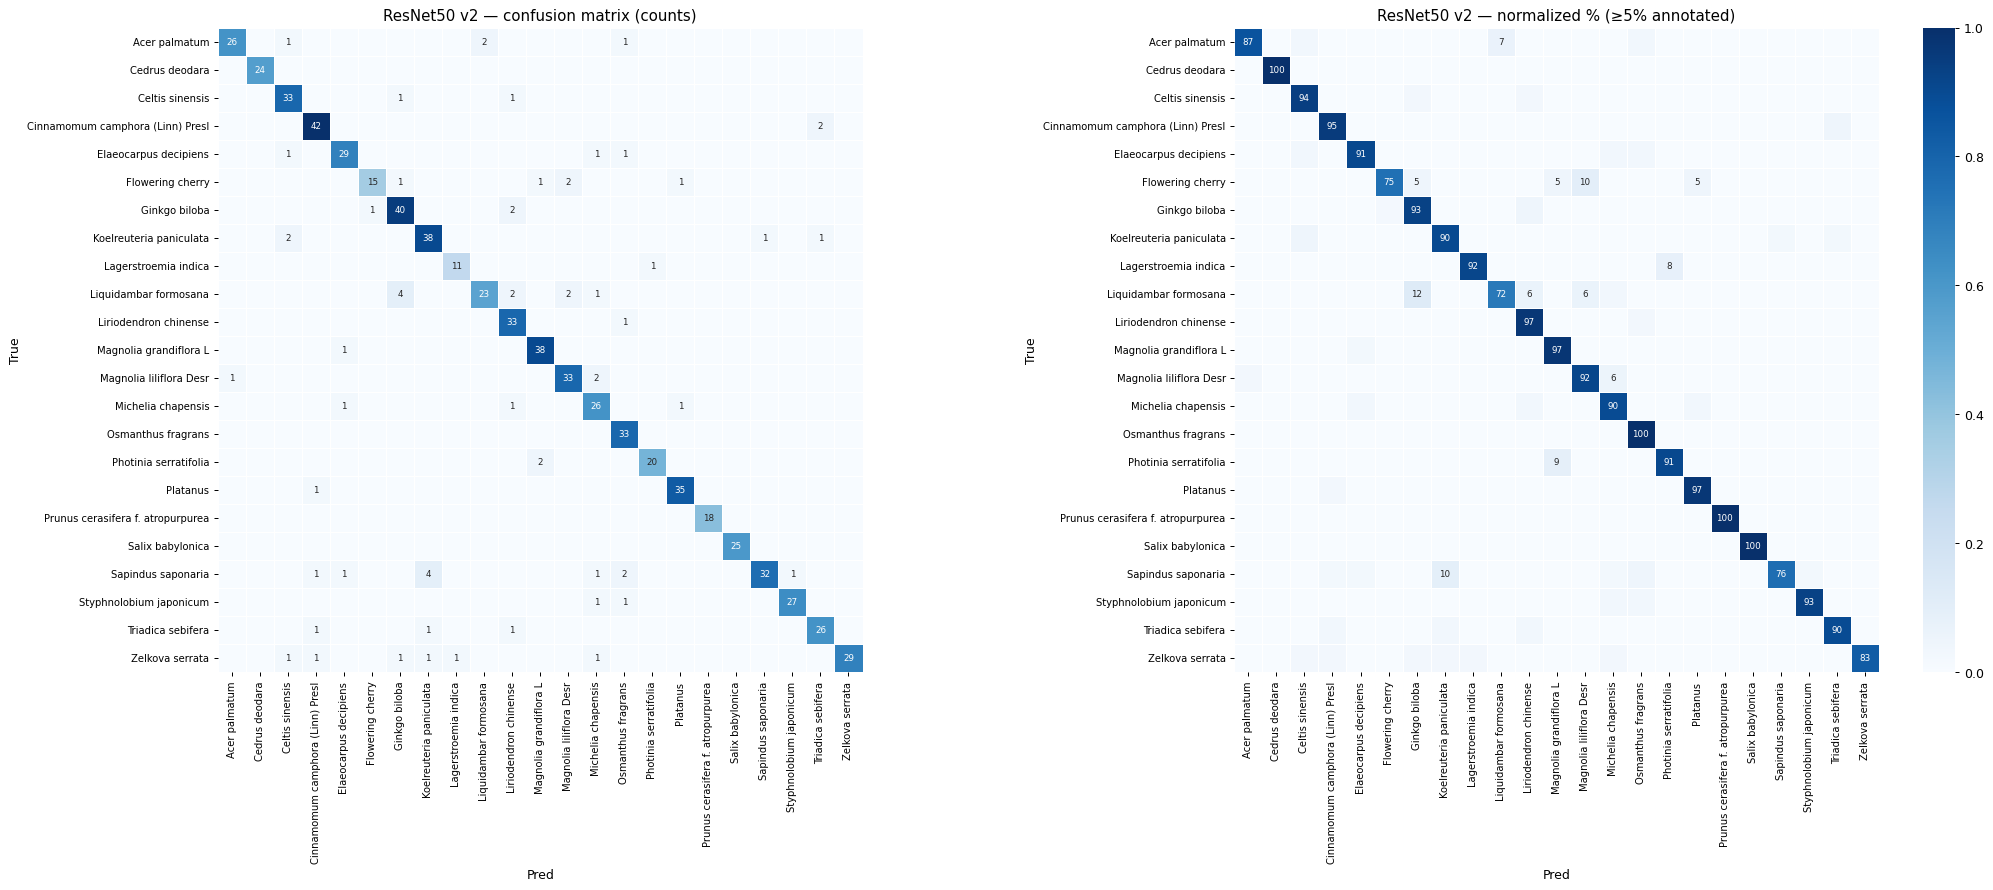

--- ResNet50 v2: most common errors (true → predicted) ---
  4   Sapindus saponaria  →  Koelreuteria paniculata
  4   Liquidambar formosana  →  Ginkgo biloba
  2   Sapindus saponaria  →  Osmanthus fragrans
  2   Photinia serratifolia  →  Magnolia grandiflora L
  2   Magnolia liliflora Desr  →  Michelia chapensis
  2   Liquidambar formosana  →  Magnolia liliflora Desr
  2   Liquidambar formosana  →  Liriodendron chinense
  2   Koelreuteria paniculata  →  Celtis sinensis
  2   Ginkgo biloba  →  Liriodendron chinense
  2   Flowering cherry  →  Magnolia liliflora Desr


In [38]:
show_confusion_matrices("ResNet50 v2")
most_confused("ResNet50 v2")

## 12. Final comparison

In [39]:
summary = pd.DataFrame({name: {k: r[k] for k in ["accuracy", "precision", "recall", "f1"]}
                        for name, r in results.items()}).T
summary.round(4)

,accuracy,precision,recall,f1
ResNet18,0.8890,0.9058,0.8918,0.8937
ResNet50,0.9057,0.9179,0.9048,0.9072
ResNet18 v2,0.8669,0.8822,0.8703,0.8687
ResNet50 v2,0.9098,0.9194,0.9108,0.9122


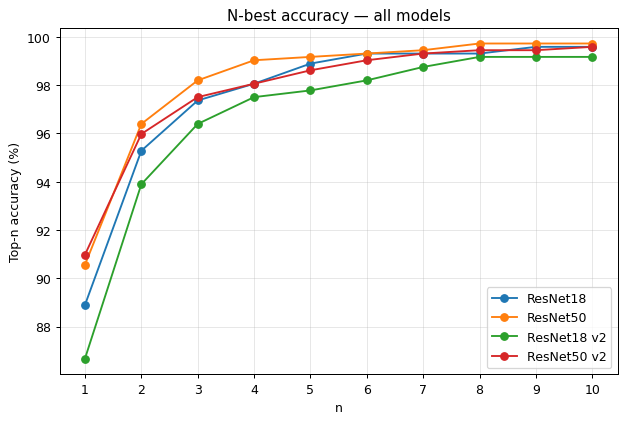

Round 2: n where ResNet50 v2 and ResNet18 v2 differ by at least 1 %-point: [1, 2, 3]


,ResNet18,ResNet50,ResNet18 v2,ResNet50 v2
n,,,,
1,88.90,90.57,86.69,90.98
2,95.28,96.39,93.90,95.98
3,97.36,98.20,96.39,97.50
4,98.06,99.03,97.50,98.06
5,98.89,99.17,97.78,98.61
6,99.31,99.31,98.20,99.03
7,99.31,99.45,98.75,99.31
8,99.31,99.72,99.17,99.45
9,99.58,99.72,99.17,99.45


In [40]:
all_names = list(results.keys())
nbest_all = pd.DataFrame({name: [top_n_accuracy(results[name]["probs"], results[name]["y_true"], n) * 100 for n in ns]
                          for name in all_names}, index=pd.Index(ns, name="n"))

plt.figure(figsize=(8, 5))
for name in all_names:
    plt.plot(ns, nbest_all[name], marker="o", label=name)
plt.xlabel("n"); plt.ylabel("Top-n accuracy (%)"); plt.title("N-best accuracy — all models")
plt.xticks(ns); plt.grid(True, alpha=0.3); plt.legend(); plt.show()

diff_v2 = nbest_all["ResNet50 v2"] - nbest_all["ResNet18 v2"]
print("Round 2: n where ResNet50 v2 and ResNet18 v2 differ by at least 1 %-point:",
      [n for n in ns if abs(diff_v2[n]) >= 1.0])
nbest_all.round(2)

## Conclusions


- **Round 1:** ResNet18 test accuracy 88.90 %, ResNet50 90.57%. The bigger model was clearly better because its deeper residual architecture
- **N-best:** tAt n = 1 ResNet50 is approximately 1.7 %-points better than ResNet18. The difference stays over 1 %-point up to n = 2; after that (starting from n = 3), the performance difference between the models drops below 1.0 %-point, and both models achieve over 96 % top-n accuracy. Therefore, n-best does not meaningfully separate the models beyond n = 2.
- **Repeating errors:** species Liquidambar formosana  →  Ginkgo biloba were mixed up both with ResNet18 and ResNet50 impossible to say why from photos
- **Round 2:** the changes (crop scale, color jitter, rotation, label smoothing, more epochs) changed test accuracy by 0 %-points for ResNet50 and for ResNet18 -2 %-points
- **Ideas we did not try:** larger input size (e.g. 320 px), class weights for the smallest classes,
  cropping the tree with an object detector before classification, test-time augmentation, EfficientNet.

Trained models: https://drive.google.com/drive/folders/1m3ppYQ8aP8y_xxPuwrz74WMe8Uz7n0Nk?usp=drive_link